# SIGK Projekt 2 - Low light image enhancement
Zespół **FakeNews**
- Marcin Wawrzyniak
- Hubert Brzóskniewicz

## Importy

In [47]:
import os
import rawpy
import imageio
import numpy as np
import pandas as pd
from tqdm import tqdm
import requests
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import matplotlib.pyplot as plt
from torchvision.utils import save_image
from skimage.metrics import peak_signal_noise_ratio as compute_psnr
from skimage.metrics import structural_similarity as compute_ssim
import lpips
from PIL import Image, ImageDraw, ImageFont

## Przygotowanie danych

### Uzupełnienie kodu z treści zadania

In [39]:
def get_ground_truth(raw):
    """
    Generates the properly exposed, full-color sRGB image (Ground Truth).
    half_size=True is used to speed up processing during training/experiments.
    """
    return raw.postprocess(use_camera_wb=True, half_size=True)

def add_physical_noise(linear_img, alpha=0.001, sigma=0.005):
    """
    Simulates physical camera sensor noise.
    alpha: controls Poisson (photon) noise
    sigma: controls Gaussian (electronic read) noise
    """
    noisy_img = np.random.poisson(linear_img / alpha) * alpha
    noisy_img += np.random.normal(0, sigma, linear_img.shape)
    return np.clip(noisy_img, 0.0, 1.0)

def get_linear_image(raw):
    """
    Extracts the linear image from RAW data.
    Disables auto-brightness and gamma correction.
    Returns a float32 image in the range [0.0, 1.0].
    """
    linear_16bit = raw.postprocess(
        use_camera_wb=True,
        gamma=(1, 1),
        no_auto_bright=True,
        output_bps=16,
        half_size=True
    )
    return linear_16bit.astype(np.float32) / 65535.0

def reduce_exposure(linear_img, ev_shift):
    """
    TODO: Simulate exposure reduction.
    Hint: A change of -1 EV halves the amount of light.
    Calculate the scale factor based on 'ev_shift' and multiply the image by it.
    """
    scale_factor = 2.0 ** ev_shift
    return linear_img * scale_factor

def apply_gamma_correction(img, gamma=2.2):
    """
    TODO: Apply sRGB gamma correction.
    Hint: The simplified formula for gamma correction is image ^ (1 / gamma).
    """
    return np.power(np.clip(img, 0.0, 1.0), 1.0 / gamma)

def convert_to_8bit(img):
    """
    TODO: Convert the float image (range 0.0 to 1.0) to an 8-bit integer (range 0 to 255).
    Ensure the returned array has the dtype np.uint8.
    """
    return np.clip(np.round(img * 255.0), 0, 255).astype(np.uint8)

def get_low_light(raw, ev_shift=-3.0):
    """
    Generates the degraded, low-light input image.
    Students must complete the helper functions above to make this pipeline work.
    """
    # Step 1: Get linear image data
    linear_img = get_linear_image(raw)
    # Step 2: Mathematically reduce the exposure
    dark_linear = reduce_exposure(linear_img, ev_shift)
    # Step 3: Add physical sensor noise
    noisy_dark_linear = add_physical_noise(dark_linear)
    # Step 4: Apply gamma curve for correct display
    dark_srgb = apply_gamma_correction(noisy_dark_linear)
    # Step 5: Convert back to standard 8-bit format
    final_8bit = convert_to_8bit(dark_srgb)
    return final_8bit

def process_single_file(file_path, output_gt_dir, output_dark_dir, ev_shift):
    base_name = os.path.splitext(os.path.basename(file_path))[0]
    gt_path = os.path.join(output_gt_dir, f"{base_name}_gt.png")
    dark_path = os.path.join(output_dark_dir, f"{base_name}_input.png")

    if os.path.exists(gt_path) and os.path.exists(dark_path):
        print(f"Skipping {base_name} - already processed.")
        return

    print(f"Processing {base_name}...")
    try:
        with rawpy.imread(file_path) as raw:
            img_gt = get_ground_truth(raw)
            img_dark = get_low_light(raw, ev_shift)
            imageio.imsave(gt_path, img_gt)
            imageio.imsave(dark_path, img_dark)
    except Exception as e:
        print(f"Error processing {base_name}: {e}")

### Pobranie danych

In [40]:
CURRENT_DIR = "./"
DATA_DIR = os.path.join(CURRENT_DIR, "data")
CSV_DATA_FILE = os.path.join(DATA_DIR, "RAISE_258.csv")
RAW_DATA_DIR = os.path.join(DATA_DIR, "raw")
PROCESSED_DATA_DIR = os.path.join(DATA_DIR, "processed")

def download_raise_files(csv_path: str, output_dir: str) -> None:
    df: pd.DataFrame = pd.read_csv(csv_path)
    os.makedirs(output_dir, exist_ok=True)

    subset_df: pd.DataFrame = df.head(100)

    row: pd.Series
    for _, row in tqdm(subset_df.iterrows(), total=len(subset_df)):
        url: str = str(row["NEF"])

        file_name: str = os.path.basename(url)
        file_path: str = os.path.join(output_dir, file_name)

        if not os.path.exists(file_path):
            response: requests.Response = requests.get(url, stream=True)
            if response.status_code == 200:
                with open(file_path, 'wb') as f:
                    chunk: bytes
                    for chunk in response.iter_content(chunk_size=8192):
                        f.write(chunk)

download_raise_files(CSV_DATA_FILE, RAW_DATA_DIR)

100%|██████████| 100/100 [00:00<00:00, 7143.50it/s]


### Generowanie zbioru danych

In [41]:
def prepare_raise_dataset(csv_file_name: str, source_dir: str, output_dir: str, ev_shift: float = -3.0) -> None:
    df: pd.DataFrame = pd.read_csv(csv_file_name)

    subset_df: pd.DataFrame = df.head(100)
    train_df: pd.DataFrame = subset_df.iloc[:80]
    test_df: pd.DataFrame = subset_df.iloc[80:]

    train_gt: str = os.path.join(output_dir, "train/gt")
    train_dark: str = os.path.join(output_dir, "train/dark")
    test_gt: str = os.path.join(output_dir, "test/gt")
    test_dark: str = os.path.join(output_dir, "test/dark")

    d: str
    for d in [train_gt, train_dark, test_gt, test_dark]:
        os.makedirs(d, exist_ok=True)

    def process_subset(data_frame: pd.DataFrame, gt_dir: str, dark_dir: str, desc: str) -> None:
        print(f"Przetwarzanie zbioru: {desc}")
        for _, row in tqdm(data_frame.iterrows(), total=len(data_frame)):
            file_name: str = str(row['File']) if 'File' in data_frame.columns else str(row.iloc[0])
            file_path: str = os.path.join(source_dir, f"{file_name}.NEF")
            process_single_file(file_path, gt_dir, dark_dir, ev_shift)

    process_subset(train_df, train_gt, train_dark, "Treningowy (80)")
    process_subset(test_df, test_gt, test_dark, "Testowy (20)")
    print("Gotowe!")

prepare_raise_dataset(csv_file_name=CSV_DATA_FILE, source_dir=RAW_DATA_DIR, output_dir=PROCESSED_DATA_DIR)

Przetwarzanie zbioru: Treningowy (80)


100%|██████████| 80/80 [00:00<00:00, 4445.24it/s]


Skipping rfcf40796t - already processed.
Skipping ra5689909t - already processed.
Skipping r5714d7e2t - already processed.
Skipping r286398d1t - already processed.
Skipping r2f686f2ct - already processed.
Skipping reaead240t - already processed.
Skipping rc204d944t - already processed.
Skipping r1ced1907t - already processed.
Skipping r3c238fbbt - already processed.
Skipping rf9565175t - already processed.
Skipping rcffd112dt - already processed.
Skipping r35ddb730t - already processed.
Skipping r8d970f8ft - already processed.
Skipping rd7da5109t - already processed.
Skipping rfc7c97b4t - already processed.
Skipping rb1bee05ft - already processed.
Skipping r49c201d2t - already processed.
Skipping rf8319011t - already processed.
Skipping r3e8f32cdt - already processed.
Skipping r14df59fet - already processed.
Skipping r5d97aeb9t - already processed.
Skipping rd15606ect - already processed.
Skipping r9c4179fft - already processed.
Skipping r37afc519t - already processed.
Skipping re6b950

100%|██████████| 20/20 [00:00<00:00, 4000.67it/s]

Skipping rc589a8d6t - already processed.
Skipping r8e60f7d2t - already processed.
Skipping r19d72b0ct - already processed.
Skipping r5211d294t - already processed.
Skipping r683da315t - already processed.
Skipping r26241ddat - already processed.
Skipping r754ef33et - already processed.
Skipping re3555814t - already processed.
Skipping rc1d2751dt - already processed.
Skipping re225f1aet - already processed.
Skipping r53dd949dt - already processed.
Skipping r43b830fet - already processed.
Skipping rdc8024e3t - already processed.
Skipping r7964e5f8t - already processed.
Skipping r35f565f8t - already processed.
Skipping r2f910937t - already processed.
Skipping re85476c1t - already processed.
Skipping rbfdec6c7t - already processed.
Skipping redaf7d93t - already processed.
Skipping r02e1abe2t - already processed.
Gotowe!


### Klasa dataset

In [42]:
class RaiseDataset(Dataset):
    def __init__(self, dark_dir: str, gt_dir: str, transform = None) -> None:
        self.dark_dir: str = dark_dir
        self.gt_dir: str = gt_dir
        self.transform = transform
        self.image_names: list[str] = sorted(os.listdir(dark_dir))

    def __len__(self) -> int:
        return len(self.image_names)

    def __getitem__(self, idx: int) -> tuple[torch.Tensor, torch.Tensor]:
        img_name: str = self.image_names[idx]
        dark_path: str = os.path.join(self.dark_dir, img_name)

        base_name: str = img_name.replace("_input.png", "")
        gt_path: str = os.path.join(self.gt_dir, f"{base_name}_gt.png")

        dark_img: Image.Image = Image.open(dark_path).convert("RGB")
        gt_img: Image.Image = Image.open(gt_path).convert("RGB")

        if self.transform:
            dark_tensor: torch.Tensor = self.transform(dark_img)
            gt_tensor: torch.Tensor = self.transform(gt_img)
        else:
            default_transform = transforms.ToTensor()
            dark_tensor = default_transform(dark_img)
            gt_tensor = default_transform(gt_img)

        return dark_tensor, gt_tensor

## Model

### Architektura - U-net

In [43]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int) -> None:
        super().__init__()
        self.net: nn.Sequential = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

class SimpleUNet(nn.Module):
    def __init__(self, in_channels: int = 3, out_channels: int = 3) -> None:
        super().__init__()
        self.inc: DoubleConv = DoubleConv(in_channels, 32)
        self.down1: nn.Sequential = nn.Sequential(nn.MaxPool2d(2), DoubleConv(32, 64))
        self.down2: nn.Sequential = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))

        self.up1: nn.ConvTranspose2d = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.conv1: DoubleConv = DoubleConv(128, 64)

        self.up2: nn.ConvTranspose2d = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.conv2: DoubleConv = DoubleConv(64, 32)

        self.outc: nn.Conv2d = nn.Conv2d(32, out_channels, kernel_size=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x1: torch.Tensor = self.inc(x)
        x2: torch.Tensor = self.down1(x1)
        x3: torch.Tensor = self.down2(x2)

        x: torch.Tensor = self.up1(x3)
        x = torch.cat([x, x2], dim=1)
        x = self.conv1(x)

        x = self.up2(x)
        x = torch.cat([x, x1], dim=1)
        x = self.conv2(x)

        logits: torch.Tensor = self.outc(x)
        return torch.sigmoid(logits)

### Trening

Używane urządzenie: cuda


Epoka 1/20 [Trening]: 100%|██████████| 20/20 [00:12<00:00,  1.56it/s]


Epoka 1 | Train Loss: 0.1713 | Test Loss: 0.2722
 -> Zapisano nowy najlepszy model (Test Loss: 0.2722)


Epoka 2/20 [Trening]: 100%|██████████| 20/20 [00:12<00:00,  1.64it/s]


Epoka 2 | Train Loss: 0.1277 | Test Loss: 0.1740
 -> Zapisano nowy najlepszy model (Test Loss: 0.1740)


Epoka 3/20 [Trening]: 100%|██████████| 20/20 [00:12<00:00,  1.59it/s]


... (31 outputs left out)

Epoka 19/20 [Trening]: 100%|██████████| 20/20 [00:12<00:00,  1.65it/s]


Epoka 19 | Train Loss: 0.0887 | Test Loss: 0.0827


Epoka 20/20 [Trening]: 100%|██████████| 20/20 [00:12<00:00,  1.65it/s]


Epoka 20 | Train Loss: 0.0871 | Test Loss: 0.0774
Trening zakończony. Najlepszy model zapisany w: best_model.pth


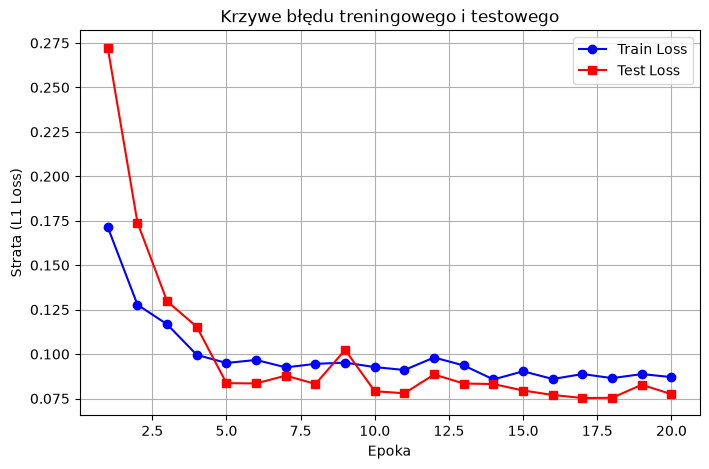

In [44]:
# Konfiguracja urządzenia (CUDA)
device: torch.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Używane urządzenie: {device}")

# Ścieżki do danych
train_dark_dir: str = os.path.join(PROCESSED_DATA_DIR, "train/dark")
train_gt_dir: str = os.path.join(PROCESSED_DATA_DIR, "train/gt")
test_dark_dir: str = os.path.join(PROCESSED_DATA_DIR, "test/dark")
test_gt_dir: str = os.path.join(PROCESSED_DATA_DIR, "test/gt")

transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor()
])

# Dataset i DataLoader dla treningu i testu
train_dataset: RaiseDataset = RaiseDataset(train_dark_dir, train_gt_dir, transform=transform)
train_loader: DataLoader = DataLoader(train_dataset, batch_size=4, shuffle=True, num_workers=0)

test_dataset: RaiseDataset = RaiseDataset(test_dark_dir, test_gt_dir, transform=transform)
test_loader: DataLoader = DataLoader(test_dataset, batch_size=4, shuffle=False, num_workers=0)

# Inicjalizacja modelu, funkcji straty i optymalizatora na CUDA
model: SimpleUNet = SimpleUNet().to(device)
criterion: nn.Module = nn.L1Loss()
optimizer: torch.optim.Optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Pętla treningowa z zapisem najlepszego modelu
num_epochs: int = 20
best_loss: float = float('inf')
model_path: str = "best_model.pth"

train_losses: list[float] = []
test_losses: list[float] = []

epoch: int
for epoch in range(num_epochs):
    # --- Faza Treningu ---
    model.train()
    running_loss: float = 0.0

    inputs: torch.Tensor
    targets: torch.Tensor
    for inputs, targets in tqdm(train_loader, desc=f"Epoka {epoch+1}/{num_epochs} [Trening]"):
        inputs = inputs.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()
        outputs: torch.Tensor = model(inputs)
        loss: torch.Tensor = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    avg_train_loss: float = running_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # --- Faza Testu (Walidacji) ---
    model.eval()
    test_running_loss: float = 0.0
    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            test_running_loss += loss.item()

    avg_test_loss: float = test_running_loss / len(test_loader)
    test_losses.append(avg_test_loss)

    print(f"Epoka {epoch+1} | Train Loss: {avg_train_loss:.4f} | Test Loss: {avg_test_loss:.4f}")

    # Zapis najlepszego modelu na podstawie błędu testowego
    if avg_test_loss < best_loss:
        best_loss = avg_test_loss
        torch.save(model.state_dict(), model_path)
        print(f" -> Zapisano nowy najlepszy model (Test Loss: {best_loss:.4f})")

print(f"Trening zakończony. Najlepszy model zapisany w: {model_path}")

# Generowanie krzywych błędu
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), train_losses, label='Train Loss', color='b', marker='o')
plt.plot(range(1, num_epochs + 1), test_losses, label='Test Loss', color='r', marker='s')
plt.title('Krzywe błędu treningowego i testowego')
plt.xlabel('Epoka')
plt.ylabel('Strata (L1 Loss)')
plt.grid(True)
plt.legend()
plt.savefig('learning_curves.png')
plt.show()

## Ewaluacja

In [51]:
# 1. Załadowanie najlepszego wytrenowanego modelu
device: torch.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model: SimpleUNet = SimpleUNet().to(device)
model.load_state_dict(torch.load("best_model.pth"))
model.eval()

# 2. Przygotowanie DataLoaderu testowego
test_dark_dir: str = os.path.join(PROCESSED_DATA_DIR, "test/dark")
test_gt_dir: str = os.path.join(PROCESSED_DATA_DIR, "test/gt")

transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor()
])

test_dataset: RaiseDataset = RaiseDataset(test_dark_dir, test_gt_dir, transform=transform)
test_loader: DataLoader = DataLoader(test_dataset, batch_size=4, shuffle=False, num_workers=0)

def evaluate_final_model(model: nn.Module, test_loader: DataLoader, device: torch.device, output_dir: str = "results_preview") -> None:
    os.makedirs(output_dir, exist_ok=True)
    loss_fn_lpips = lpips.LPIPS(net='alex').to(device)

    psnr_list: list[float] = []
    ssim_list: list[float] = []
    lpips_list: list[float] = []

    to_pil = transforms.ToPILImage()

    # Próba wczytania czcionki systemowej, w razie braku użycie domyślnej
    try:
        font = ImageFont.truetype("arial.ttf", 14)
    except IOError:
        font = ImageFont.load_default()

    with torch.no_grad():
        for idx, (inputs, targets) in enumerate(test_loader):
            inputs = inputs.to(device)
            targets = targets.to(device)

            outputs: torch.Tensor = model(inputs)

            # Zapis podpisanych próbek dla pierwszego batcha
            for i in range(inputs.size(0)):
                img_in = to_pil(inputs[i].cpu())
                img_out = to_pil(outputs[i].cpu())
                img_gt = to_pil(targets[i].cpu())

                w, h = img_in.size
                banner_height = 25

                # Utworzenie wspólnego obrazu z miejscem na napisy u góry
                combined = Image.new("RGB", (w * 3, h + banner_height), color=(255, 255, 255))
                combined.paste(img_in, (0, banner_height))
                combined.paste(img_out, (w, banner_height))
                combined.paste(img_gt, (w * 2, banner_height))

                draw = ImageDraw.Draw(combined)
                draw.text((10, 5), "Input (Dark)", fill=(0, 0, 0), font=font)
                draw.text((w + 10, 5), "Output (Model)", fill=(0, 0, 0), font=font)
                draw.text((w * 2 + 10, 5), "Ground Truth", fill=(0, 0, 0), font=font)

                combined.save(os.path.join(output_dir, f"test_sample_{idx}_{i}.png"))

            preds: np.ndarray = outputs.cpu().permute(0, 2, 3, 1).numpy()
            gts: np.ndarray = targets.cpu().permute(0, 2, 3, 1).numpy()

            for i in range(preds.shape[0]):
                psnr_list.append(compute_psnr(gts[i], preds[i], data_range=1.0))
                ssim_list.append(compute_ssim(gts[i], preds[i], data_range=1.0, channel_axis=-1, multichannel=True))

            outputs_lpips = outputs * 2.0 - 1.0
            targets_lpips = targets * 2.0 - 1.0
            lpips_list.extend(loss_fn_lpips(outputs_lpips, targets_lpips).cpu().numpy().flatten().tolist())

    print("--- Wyniki końcowe na zbiorze testowym ---")
    print(f"Średnie PSNR: {np.mean(psnr_list):.2f} dB")
    print(f"Średnie SSIM: {np.mean(ssim_list):.4f}")
    print(f"Średnie LPIPS: {np.mean(lpips_list):.4f}")
    print(f"Obrazy do podglądu zapisano w: {output_dir}")

# Uruchomienie ewaluacji
evaluate_final_model(model, test_loader, device)

C:\Users\Marcin\AppData\Local\Temp\ipykernel_17420\774187015.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("best_model.pth"))


Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
Loading model from: c:\Users\Marcin\Dane\studia\MGR\SIGK\SIGK\projekt_2\venv\Lib\site-packages\lpips\weights\v0.1\alex.pth
--- Wyniki końcowe na zbiorze testowym ---
Średnie PSNR: 21.87 dB
Średnie SSIM: 0.8311
Średnie LPIPS: 0.2091
Obrazy do podglądu zapisano w: results_preview
